In [1]:
! pip install opendatasets

In [2]:
pip install legacy-cgi


In [3]:
import opendatasets as od
od.download("https://www.kaggle.com/datasets/masoudnickparvar/brain-tumor-mri-dataset")

Please provide your Kaggle credentials to download this dataset. Learn more: http://bit.ly/kaggle-creds
Your Kaggle username: henishma
Your Kaggle Key: ··········
Dataset URL: https://www.kaggle.com/datasets/masoudnickparvar/brain-tumor-mri-dataset


100%|██████████| 157M/157M [00:01<00:00, 119MB/s]


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [4]:
pip install imutils

In [5]:
import os
import random
from tqdm import tqdm
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import seaborn as sns
from IPython.display import Image
import imutils

In [6]:
print(os.getcwd())

/content


In [7]:
os.mkdir("crop-brain-mri")
os.mkdir("crop-brain-mri/glioma")
os.mkdir("crop-brain-mri/meningioma")
os.mkdir("crop-brain-mri/no_tumor")
os.mkdir("crop-brain-mri/pituitary")

In [10]:
os.mkdir("Test-Data")
os.mkdir("Test-Data/glioma")
os.mkdir("Test-Data/meningioma")
os.mkdir("Test-Data/no_tumor")
os.mkdir("Test-Data/pituitary")

In [11]:
#Data visualization
train_dir="/content/brain-tumor-mri-dataset/Training"
test_dir="/content/brain-tumor-mri-dataset/Testing"

In [13]:
classes=os.listdir("/content/brain-tumor-mri-dataset/Training")
classes

['meningioma', 'notumor', 'pituitary', 'glioma']

In [14]:
filepath_dict = {}

for c in classes:
    folder_path=os.path.join(train_dir,c)
    filepath_dict[c]= [
        os.path.join(folder_path,x)
        for x in os.listdir(folder_path)
    ]

In [15]:
filepath_dict #shows all images with its path

{'meningioma': ['/content/brain-tumor-mri-dataset/Training/meningioma/Tr-me_991.jpg',
  '/content/brain-tumor-mri-dataset/Training/meningioma/Tr-me_272.jpg',
  '/content/brain-tumor-mri-dataset/Training/meningioma/Tr-me_608.jpg',
  '/content/brain-tumor-mri-dataset/Training/meningioma/Tr-me_200.jpg',
  '/content/brain-tumor-mri-dataset/Training/meningioma/Tr-me_337.jpg',
  '/content/brain-tumor-mri-dataset/Training/meningioma/Tr-aug-me_52.jpg',
  '/content/brain-tumor-mri-dataset/Training/meningioma/Tr-me_962.jpg',
  '/content/brain-tumor-mri-dataset/Training/meningioma/Tr-me_1150.jpg',
  '/content/brain-tumor-mri-dataset/Training/meningioma/Tr-me_154.jpg',
  '/content/brain-tumor-mri-dataset/Training/meningioma/Tr-me_759.jpg',
  '/content/brain-tumor-mri-dataset/Training/meningioma/Tr-me_784.jpg',
  '/content/brain-tumor-mri-dataset/Training/meningioma/Tr-aug-me_82.jpg',
  '/content/brain-tumor-mri-dataset/Training/meningioma/Tr-me_1040.jpg',
  '/content/brain-tumor-mri-dataset/Traini

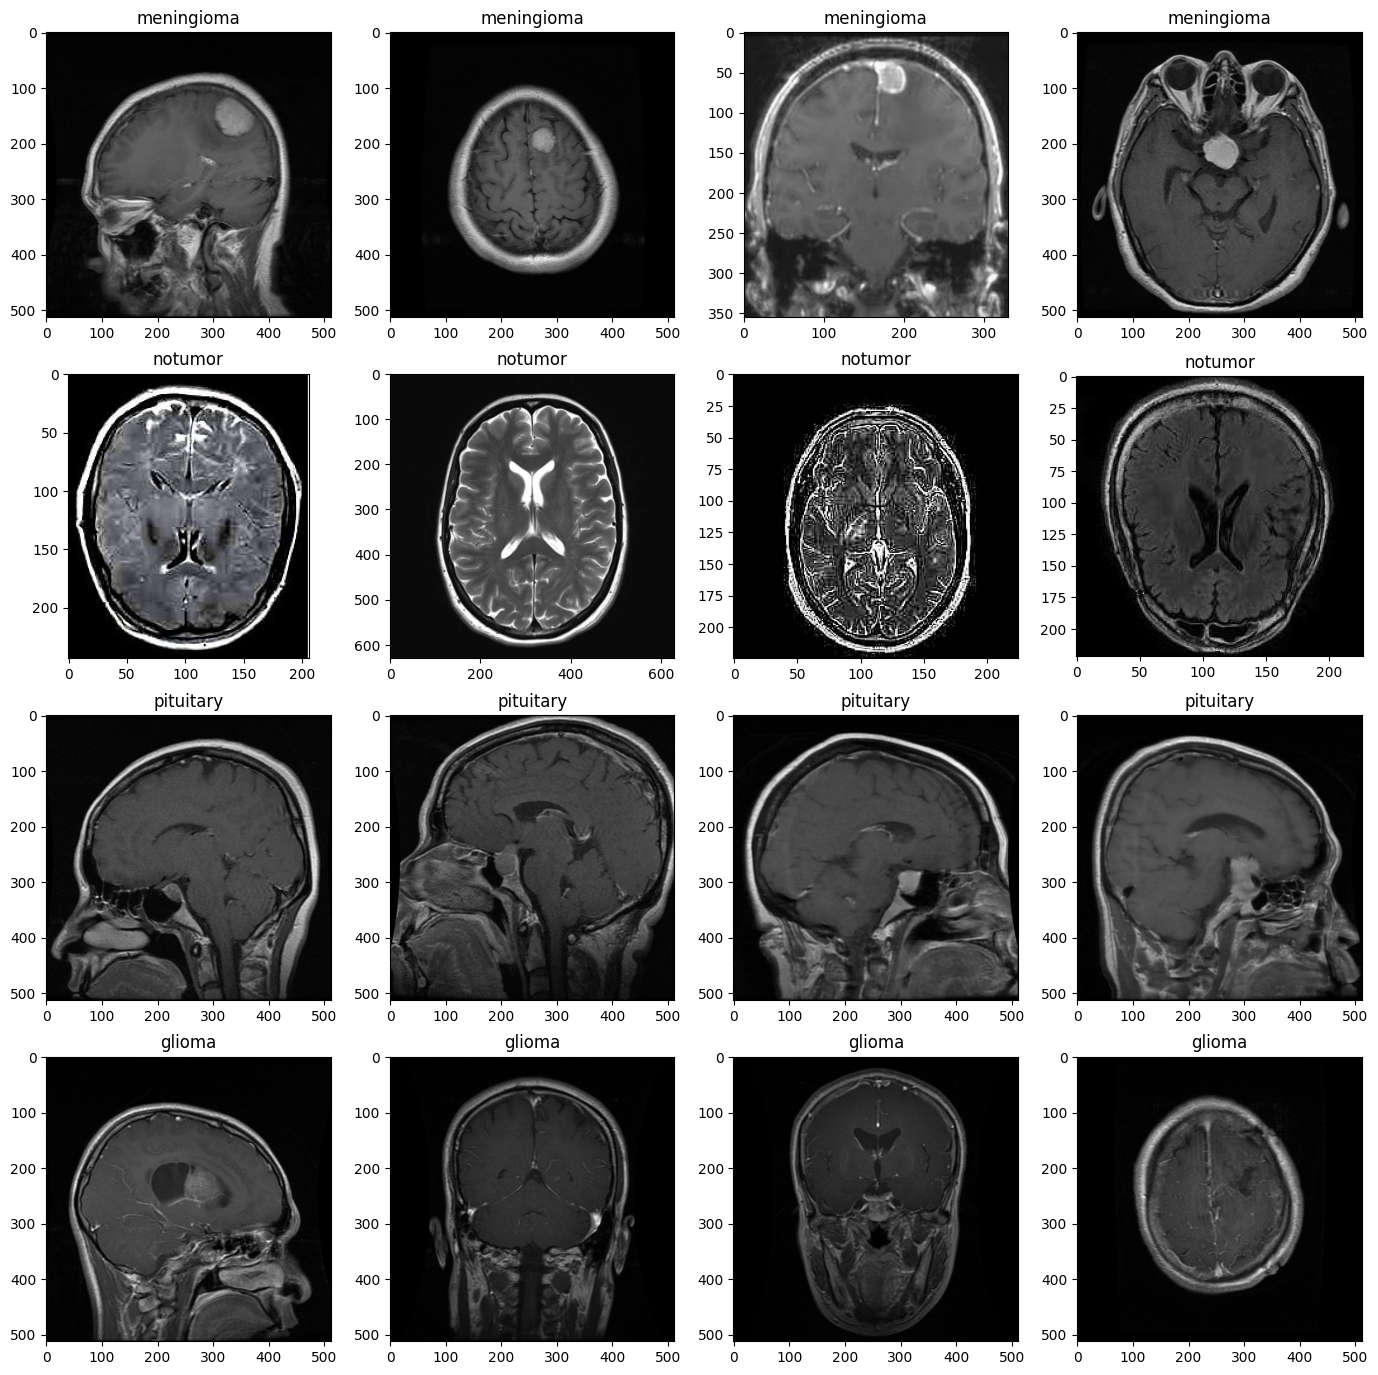

In [16]:
from tensorflow.keras.preprocessing.image import load_img
plt.figure(figsize=(17,17))

index=0

for c in classes:
    random.shuffle(filepath_dict[c])
    path_list=filepath_dict[c][:5]

    for i in range(1,5):
        index+=1
        plt.subplot(4,4,index)
        plt.imshow(load_img(path_list[i]))
        plt.title(c)

In [17]:
no_images_per_class=[]
class_name=[]
for i in os.listdir(train_dir):
    train_class= os.listdir(os.path.join(train_dir,i))
    no_images_per_class.append(len(train_class))
    class_name.append(i)
    print(f"Number of images in {i} : {len(train_class)}")

Number of images in meningioma : 1400
Number of images in notumor : 1400
Number of images in pituitary : 1400
Number of images in glioma : 1400


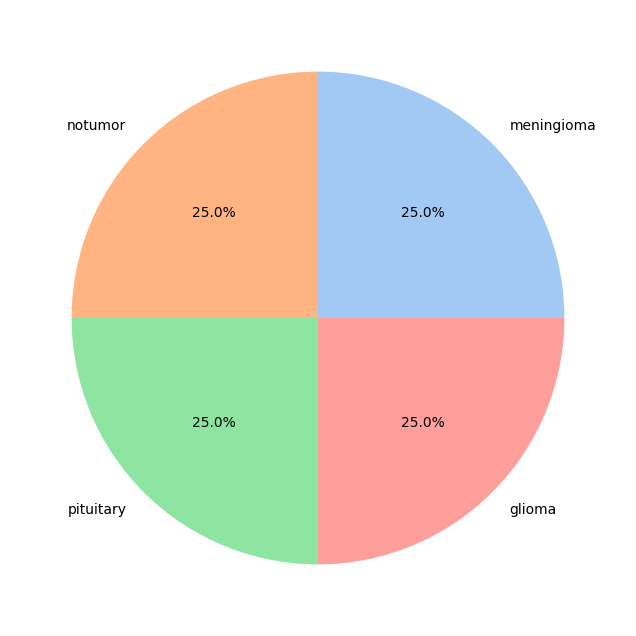

In [18]:
plt.figure(figsize=(8,8))
colors=sns.color_palette('pastel')
plt.pie(no_images_per_class,labels=class_name,autopct="%1.1f%%",colors=colors)
plt.show()

In [19]:

# Crop images to remove unwanted background

def crop_images(image, plot=False):

    # Convert image to grayscale
    img_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    # Apply Gaussian Blur to remove noise
    img_gray = cv2.GaussianBlur(img_gray, (5, 5), 0)

    # Apply binary thresholding
    img_thresh = cv2.threshold(
        img_gray, 45, 255, cv2.THRESH_BINARY
    )[1]

    # Apply morphological opening (erosion + dilation)
    img_thresh = cv2.erode(img_thresh, None, iterations=2)
    img_thresh = cv2.dilate(img_thresh, None, iterations=2)

    # Find contours
    contours = cv2.findContours(
        img_thresh.copy(),
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_NONE
    )

    # Extract contours (handles different OpenCV versions)
    contours = imutils.grab_contours(contours)

    # Check whether any contours were detected
    if len(contours) == 0:
        return image

    # Find the largest contour
    c = max(contours, key=cv2.contourArea)

    # Find the four extreme points
    extLeft = tuple(c[c[:, :, 0].argmin()][0])
    extRight = tuple(c[c[:, :, 0].argmax()][0])
    extTop = tuple(c[c[:, :, 1].argmin()][0])
    extBottom = tuple(c[c[:, :, 1].argmax()][0])

    # Crop the original image using the extreme points
    new_img = image[
        extTop[1]:extBottom[1],
        extLeft[0]:extRight[0]
    ]

    # Display original and cropped images
    if plot:
        plt.figure(figsize=(15, 6))

        plt.subplot(1, 2, 1)
        plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
        plt.title("Original Image")
        plt.axis("off")

        plt.subplot(1, 2, 2)
        plt.imshow(cv2.cvtColor(new_img, cv2.COLOR_BGR2RGB))
        plt.title("Cropped Image")
        plt.axis("off")

        plt.show()

    return new_img


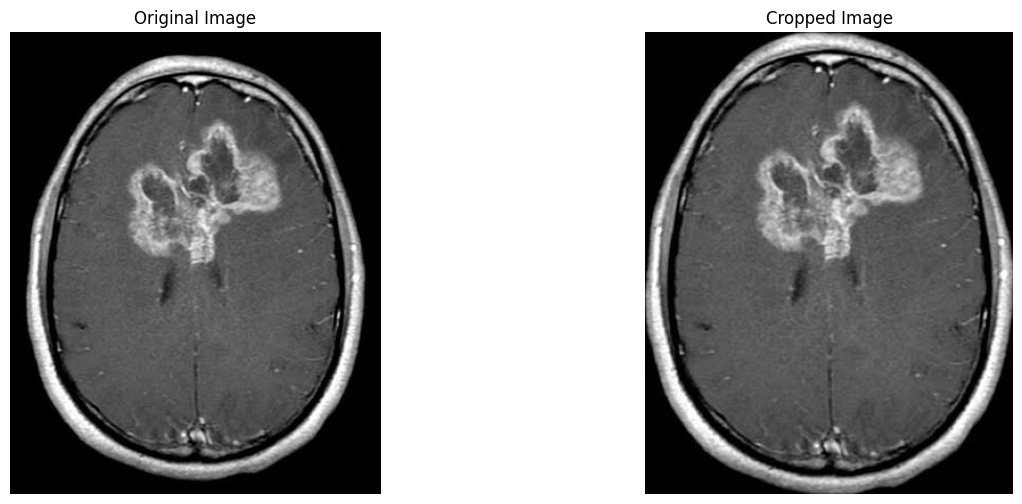

In [20]:
example_img= cv2.imread("/content/brain-tumor-mri-dataset/Testing/glioma/Te-gl_1.jpg")
cropped_imgs=crop_images(example_img,plot=True)

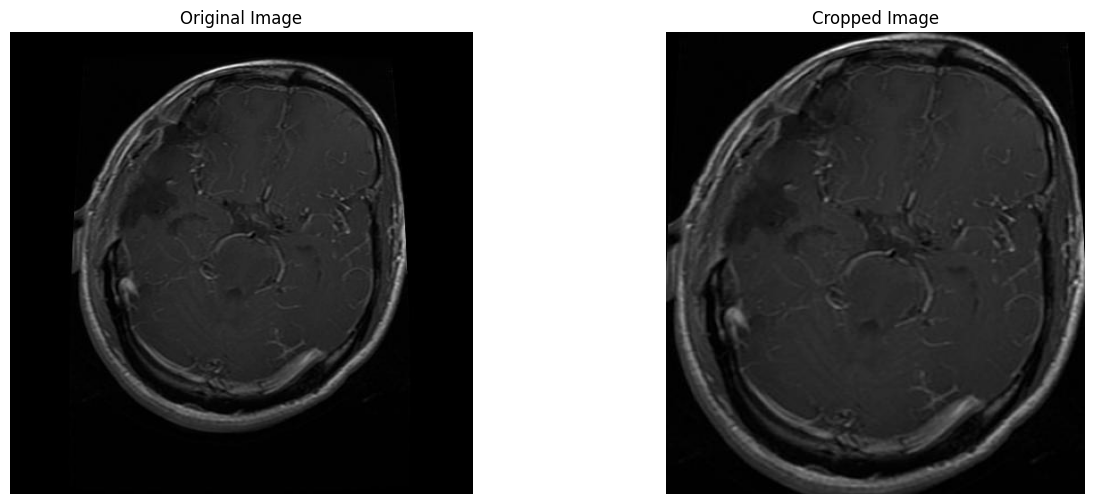

In [22]:
exp2=cv2.imread("/content/brain-tumor-mri-dataset/Testing/glioma/Te-gl_52.jpg")
cropped_img2=crop_images(exp2,plot=True)

In [23]:

glioma = os.path.join(train_dir, "glioma")
meningioma = os.path.join(train_dir, "meningioma")
no_tumor = os.path.join(train_dir, "notumor")
pituitary = os.path.join(train_dir, "pituitary")

j = 0

save_dir = '/content/crop-brain-mri/glioma'

os.makedirs(save_dir, exist_ok=True)

for i in tqdm(os.listdir(glioma)):

    path = os.path.join(glioma, i)

    img = cv2.imread(path)

    if img is not None:

        img = crop_images(img, plot=False)

        img = cv2.resize(img, (240, 240))

        save_path = os.path.join(save_dir, str(j) + '.jpg')

        cv2.imwrite(save_path, img)

        j += 1


100%|██████████| 1400/1400 [00:03<00:00, 368.29it/s]


In [24]:


j = 0

save_dir = '/content/crop-brain-mri/meningioma'

os.makedirs(save_dir, exist_ok=True)

for i in tqdm(os.listdir(meningioma)):

    path = os.path.join(meningioma, i)

    img = cv2.imread(path)

    if img is not None:

        img = crop_images(img, plot=False)

        img = cv2.resize(img, (240, 240))

        save_path = os.path.join(save_dir, str(j) + '.jpg')

        cv2.imwrite(save_path, img)

        j += 1


100%|██████████| 1400/1400 [00:04<00:00, 340.98it/s]


In [25]:


j = 0

save_dir = '/content/crop-brain-mri/pituitary'

os.makedirs(save_dir, exist_ok=True)

for i in tqdm(os.listdir(pituitary)):

    path = os.path.join(pituitary, i)

    img = cv2.imread(path)

    if img is not None:

        img = crop_images(img, plot=False)

        img = cv2.resize(img, (240, 240))

        save_path = os.path.join(save_dir, str(j) + '.jpg')

        cv2.imwrite(save_path, img)

        j += 1


100%|██████████| 1400/1400 [00:04<00:00, 318.68it/s]


In [30]:


j = 0

save_dir = '/content/crop-brain-mri/no_tumor'

os.makedirs(save_dir, exist_ok=True)

for i in tqdm(os.listdir(no_tumor)):

    path = os.path.join(no_tumor, i)

    img = cv2.imread(path)

    if img is not None:

        img = crop_images(img, plot=False)

        img = cv2.resize(img, (240, 240))

        save_path = os.path.join(save_dir, str(j) + '.jpg')

        cv2.imwrite(save_path, img)

        j += 1


100%|██████████| 1400/1400 [00:04<00:00, 340.46it/s]


In [31]:
test_glioma = os.path.join(test_dir, "glioma")
test_meningioma = os.path.join(test_dir, "meningioma")
test_no_tumor = os.path.join(test_dir, "notumor")
test_pituitary = os.path.join(test_dir, "pituitary")


j = 0

save_dir = '/content/Test-Data/glioma'

os.makedirs(save_dir, exist_ok=True)

for i in tqdm(os.listdir(test_glioma)):

    path = os.path.join(test_glioma, i)

    img = cv2.imread(path)

    if img is not None:

        img = crop_images(img, plot=False)

        img = cv2.resize(img, (240, 240))

        save_path = os.path.join(save_dir, str(j) + '.jpg')

        cv2.imwrite(save_path, img)

        j += 1


100%|██████████| 400/400 [00:01<00:00, 249.84it/s]


In [32]:

j = 0

save_dir = '/content/Test-Data/meningioma'

os.makedirs(save_dir, exist_ok=True)

for i in tqdm(os.listdir(test_meningioma)):

    path = os.path.join(test_meningioma, i)

    img = cv2.imread(path)

    if img is not None:

        img = crop_images(img, plot=False)

        img = cv2.resize(img, (240, 240))

        save_path = os.path.join(save_dir, str(j) + '.jpg')

        cv2.imwrite(save_path, img)

        j += 1


100%|██████████| 400/400 [00:01<00:00, 291.06it/s]


In [33]:

j = 0

save_dir = '/content/Test-Data/no_tumor'

os.makedirs(save_dir, exist_ok=True)

for i in tqdm(os.listdir(test_no_tumor)):

    path = os.path.join(test_no_tumor, i)

    img = cv2.imread(path)

    if img is not None:

        img = crop_images(img, plot=False)

        img = cv2.resize(img, (240, 240))

        save_path = os.path.join(save_dir, str(j) + '.jpg')

        cv2.imwrite(save_path, img)

        j += 1


100%|██████████| 400/400 [00:01<00:00, 236.08it/s]


In [34]:

j = 0

save_dir = '/content/Test-Data/pituitary'

os.makedirs(save_dir, exist_ok=True)

for i in tqdm(os.listdir(test_pituitary)):

    path = os.path.join(test_pituitary, i)

    img = cv2.imread(path)

    if img is not None:

        img = crop_images(img, plot=False)

        img = cv2.resize(img, (240, 240))

        save_path = os.path.join(save_dir, str(j) + '.jpg')

        cv2.imwrite(save_path, img)

        j += 1


100%|██████████| 400/400 [00:01<00:00, 318.87it/s]


In [35]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator, array_to_img, img_to_array



In [39]:
import os
import shutil

checkpoint_path = "/content/crop-brain-mri/.ipynb_checkpoints"

if os.path.exists(checkpoint_path):
    shutil.rmtree(checkpoint_path)
    print("Checkpoint folder removed!")

Checkpoint folder removed!


In [54]:
datagen= ImageDataGenerator(rotation_range=10,
                           height_shift_range=0.2,
                           horizontal_flip=True,
                           validation_split=0.2)
train_data= datagen.flow_from_directory("/content/crop-brain-mri",
                            target_size=(240,240),
                            batch_size=32,
                            class_mode='categorical',subset='training')

valid_data= datagen.flow_from_directory("/content/crop-brain-mri",
                            target_size=(240,240),
                            batch_size=32,
                            class_mode='categorical',subset='validation')
test_datagen=ImageDataGenerator()



test_data= datagen.flow_from_directory("/content/Test-Data",
                           target_size=(240,240),
                           class_mode='categorical',shuffle=False)


Found 4480 images belonging to 4 classes.
Found 1120 images belonging to 4 classes.
Found 1600 images belonging to 4 classes.


In [41]:
train_data.class_indices

{'glioma': 0, 'meningioma': 1, 'no_tumor': 2, 'pituitary': 3}

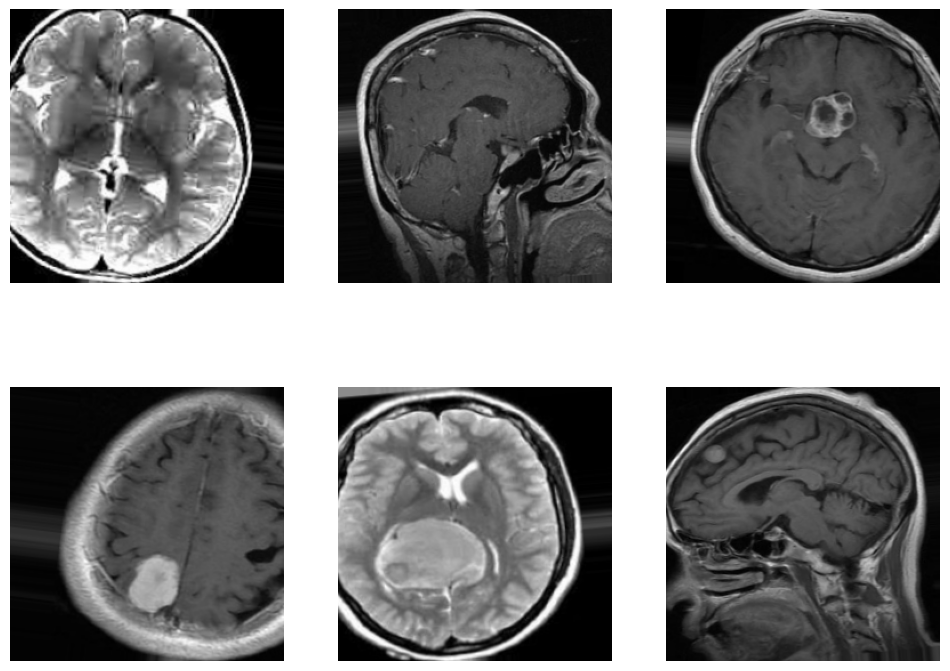

In [42]:
sample_x,sample_y =next(train_data)
plt.figure(figsize=(12,9))
for i in range(6):
    plt.subplot(2,3,i+1)
    sample=array_to_img(sample_x[i])
    plt.axis('off')
    plt.grid(False)
    plt.imshow(sample)

plt.show()

In [43]:
#use efficientNet model

import tensorflow as tf
from tensorflow.keras.applications import EfficientNetB1
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Flatten, Dense, Conv2D,Dropout,GlobalMaxPooling2D
from tensorflow.keras.callbacks import ModelCheckpoint,EarlyStopping,ReduceLROnPlateau

In [44]:
effenet=EfficientNetB1(weights='imagenet',include_top=False,input_shape=(240,240,3))
model=effenet.output
model=GlobalMaxPooling2D()(model)
model=Dropout(0.5)(model)
model=Dense(4,activation="softmax")(model)
model=Model(inputs=effenet.input,outputs=model)
model.summary()


27018416/27018416 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 240, 240,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling           │ (None, 240, 240,  │          0 │ input_layer[0][0] │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalization       │ (None, 240, 240,  │          7 │ rescaling[0][0]   │
│ (Normalization)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_1         │ (None, 240, 240,  │          0 │ normalization[0]… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv_pad       │ (None, 241, 241,  │          0 │ rescaling_1[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv (Conv2D)  │ (None, 120, 120,  │        864 │ stem_conv_pad[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_bn             │ (None, 120, 120,  │        128 │ stem_conv[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_activation     │ (None, 120, 120,  │          0 │ stem_bn[0][0]     │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_dwconv      │ (None, 120, 120,  │        288 │ stem_activation[… │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_bn          │ (None, 120, 120,  │        128 │ block1a_dwconv[0… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_activation  │ (None, 120, 120,  │          0 │ block1a_bn[0][0]  │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_squeeze  │ (None, 32)        │          0 │ block1a_activati… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reshape  │ (None, 1, 1, 32)  │          0 │ block1a_se_squee… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reduce   │ (None, 1, 1, 8)   │        264 │ block1a_se_resha… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_expand   │ (None, 1, 1, 32)  │        288 │ block1a_se_reduc… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_excite   │ (None, 120, 120,  │          0 │ block1a_activati… │
│ (Multiply)          │ 32)               │            │ block1a_se_expan… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_project_co… │ (None, 120, 120,  │        512 │ block1a_se_excit

 Total params: 6,580,363 (25.10 MB)

 Trainable params: 6,518,308 (24.87 MB)

 Non-trainable params: 62,055 (242.41 KB)

In [45]:
from tensorflow.keras.optimizers import Adam

In [46]:
model.compile(optimizer=Adam(learning_rate=0.0001),
             loss='categorical_crossentropy',
             metrics=['accuracy'])
checkpoint=ModelCheckpoint('model.keras',monitor='val_accuracy',
               save_best_only=True,
               mode='auto',
               verbose=1)
earlystop=EarlyStopping(monitor='val_accuracy',
             patience=5,
             mode='auto',verbose=1)
reduce_lr=ReduceLROnPlateau(monitor='val_accuracy',
                 factor=0.3,
                 patience=2,
                 min_delta=0.001,
                 mode='auto',verbose=1)


In [47]:
%%time
history=model.fit(train_data,epochs=20,validation_data=valid_data,
                 verbose=1,
                 callbacks=[checkpoint,earlystop,reduce_lr])

Epoch 1/20
140/140 ━━━━━━━━━━━━━━━━━━━━ 0s 561ms/step - accuracy: 0.4978 - loss: 4.2014
Epoch 1: val_accuracy improved from None to 0.71875, saving model to model.keras

Epoch 1: finished saving model to model.keras
140/140 ━━━━━━━━━━━━━━━━━━━━ 291s 776ms/step - accuracy: 0.6406 - loss: 2.4544 - val_accuracy: 0.7188 - val_loss: 1.1533 - learning_rate: 1.0000e-04
Epoch 2/20
140/140 ━━━━━━━━━━━━━━━━━━━━ 0s 533ms/step - accuracy: 0.8228 - loss: 0.9592
Epoch 2: val_accuracy improved from 0.71875 to 0.72411, saving model to model.keras

Epoch 2: finished saving model to model.keras
140/140 ━━━━━━━━━━━━━━━━━━━━ 93s 665ms/step - accuracy: 0.8455 - loss: 0.8013 - val_accuracy: 0.7241 - val_loss: 1.3455 - learning_rate: 1.0000e-04
Epoch 3/20
140/140 ━━━━━━━━━━━━━━━━━━━━ 0s 537ms/step - accuracy: 0.8900 - loss: 0.4841
Epoch 3: val_accuracy improved from 0.72411 to 0.81696, saving model to model.keras

Epoch 3: finished saving model to model.keras
140/140 ━━━━━━━━━━━━━━━━━━━━ 98s 697ms/step - acc

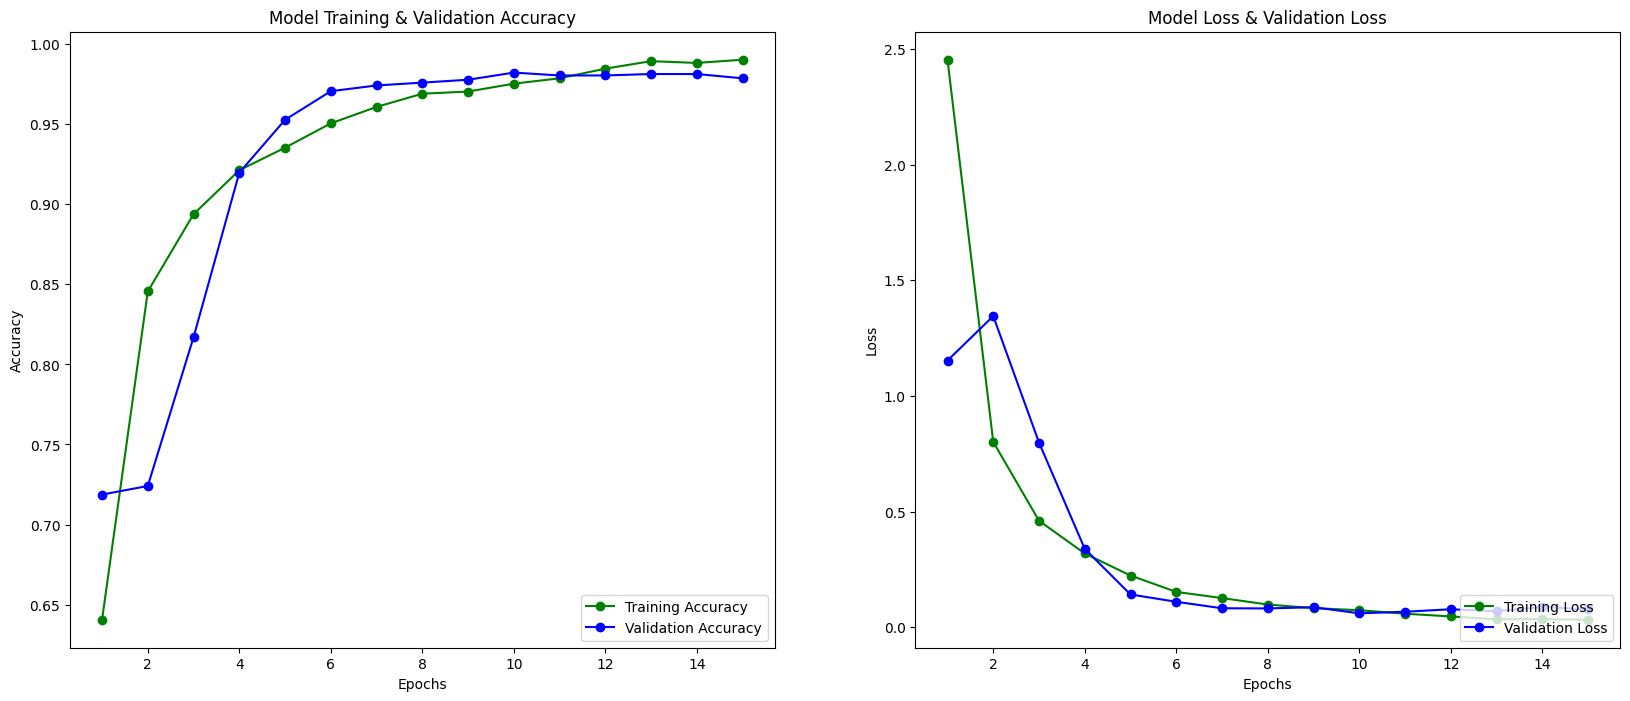

In [50]:
fig, ax = plt.subplots(1, 2)
fig.set_size_inches(20, 8)

train_acc = history.history['accuracy']
train_loss = history.history['loss']

val_acc = history.history['val_accuracy']
val_loss = history.history['val_loss']

epochs = range(1, len(train_acc) + 1)

# Accuracy plot
ax[0].plot(epochs, train_acc, 'g-o', label='Training Accuracy')
ax[0].plot(epochs, val_acc, 'b-o', label='Validation Accuracy')
ax[0].set_title('Model Training & Validation Accuracy')
ax[0].legend(loc='lower right')
ax[0].set_xlabel("Epochs")
ax[0].set_ylabel('Accuracy')

# Loss plot
ax[1].plot(epochs, train_loss, 'g-o', label='Training Loss')
ax[1].plot(epochs, val_loss, 'b-o', label='Validation Loss')
ax[1].set_title('Model Loss & Validation Loss')
ax[1].legend(loc='lower right')
ax[1].set_xlabel("Epochs")
ax[1].set_ylabel('Loss')

plt.show()

In [52]:
model.evaluate(train_data)

140/140 ━━━━━━━━━━━━━━━━━━━━ 67s 473ms/step - accuracy: 0.9989 - loss: 0.0046


[0.004602895118296146, 0.9988839030265808]

In [55]:
model.evaluate(test_data)

50/50 ━━━━━━━━━━━━━━━━━━━━ 25s 499ms/step - accuracy: 0.9525 - loss: 0.5676


[0.5676326155662537, 0.9524999856948853]

In [56]:
y_test=test_data.classes
y_test_hat=np.argmax(model.predict(test_data),axis=1)

50/50 ━━━━━━━━━━━━━━━━━━━━ 35s 502ms/step


In [57]:
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, confusion_matrix,classification_report



In [58]:
cm=confusion_matrix(y_test,y_test_hat)
cm

array([[339,  43,  17,   1],
       [  3, 393,   1,   3],
       [  0,   0, 400,   0],
       [  0,   3,   0, 397]])

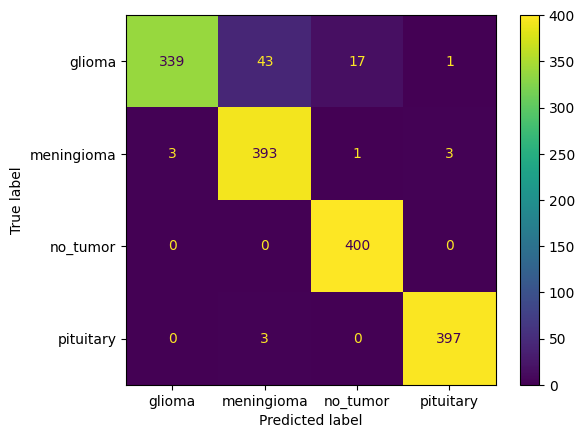

In [59]:
cm_display= ConfusionMatrixDisplay(confusion_matrix=cm, display_labels= ['glioma','meningioma','no_tumor','pituitary'])
cm_display.plot()
plt.show()

In [60]:
#Prediction on Test image

import PIL

CLASS_DICT={ 0: 'glioma', 1: 'meningioma', 2: 'no_tumor', 3: 'pituitary'}

images= []
prediction=[]
original=[]

for i in os.listdir('/content/Test-Data'):
  for item in os.listdir(os.path.join('/content/Test-Data',i)):
    img=PIL.Image.open(os.path.join('/content/Test-Data',i,item))
    images.append(img)
    img=np.expand_dims(img,axis=0)
    predict=model.predict(img)
    predict=np.argmax(predict)
    prediction.append(CLASS_DICT[predict])
    original.append(i)



1/1 ━━━━━━━━━━━━━━━━━━━━ 28s 28s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 86ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 85ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step
1/1 ━━━━━━━━

In [61]:
score= accuracy_score(original,prediction)
score

0.9525

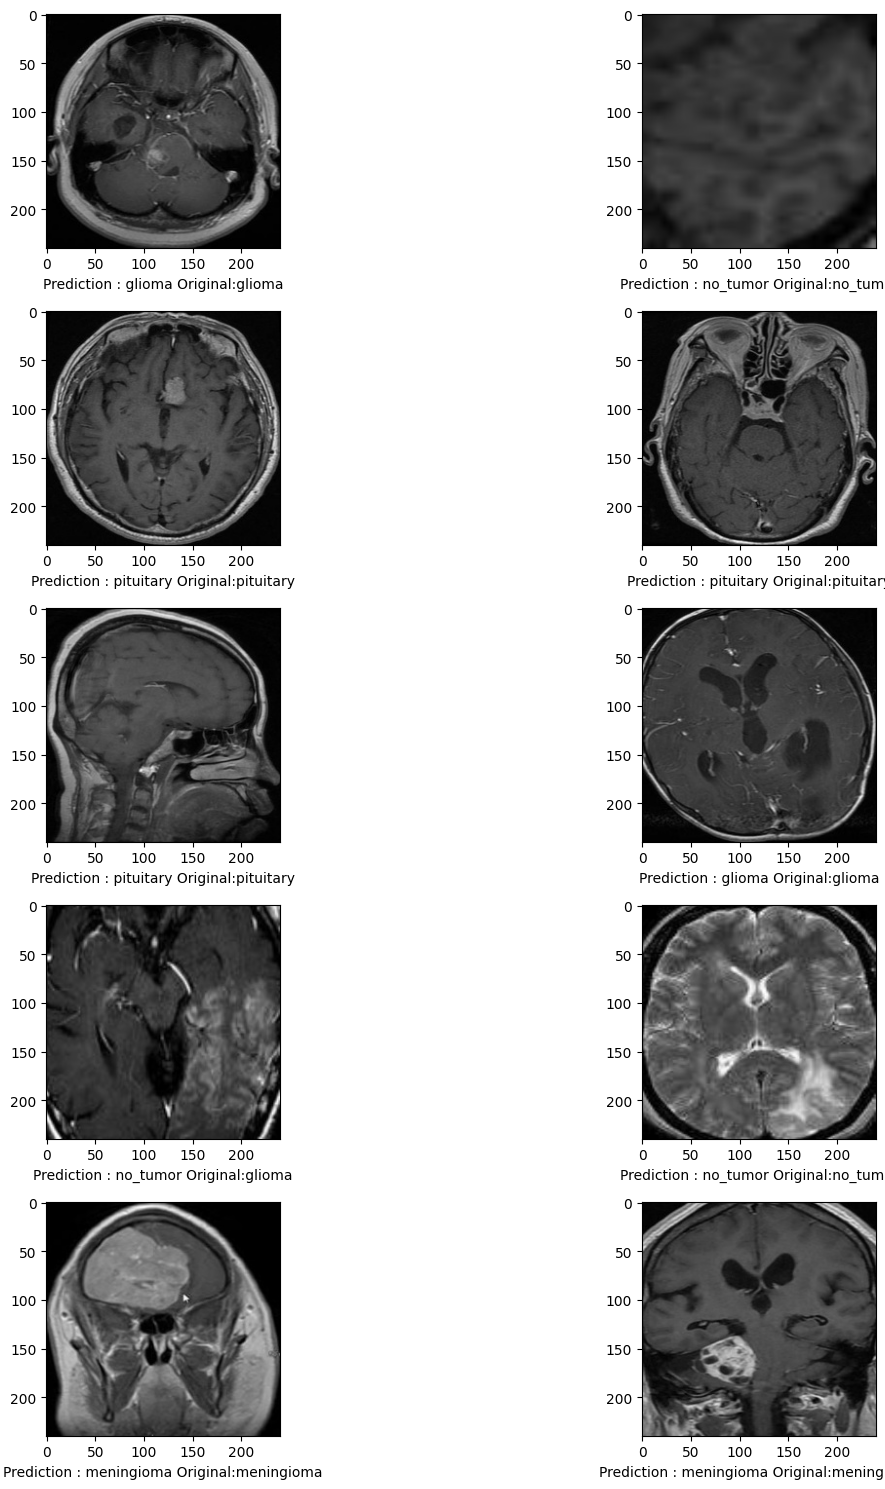

In [63]:
fig=plt.figure(figsize=(15,15))
for i in range(10):
  j=random.randint(0,len(images))
  fig.add_subplot(5,2,i+1)
  plt.xlabel("Prediction : " + prediction[j]+ " Original:"+ original[j])
  plt.imshow(images[j])
fig.tight_layout()
plt.show()

In [66]:
import tensorflow as tf
last_conv_layer= next(x for x in model.layers[::-1] if isinstance(x,tf.keras.layers.Conv2D))
last_conv_layer

<Conv2D name=top_conv, built=True>

In [67]:
# vizgradcam/gradcam.py

import cv2
import numpy as np
from PIL import Image
import tensorflow as tf
import tensorflow.keras as K
import matplotlib.pyplot as plt
from skimage.transform import resize
from tensorflow.keras.models import Model


def VizGradCAM(model, image, interpolant=0.5, plot_results=True):
    """VizGradCAM - Displays GradCAM based on Keras / TensorFlow models
    using the gradients from the last convolutional layer. This function
    should work with all Keras Application listed here:
    https://keras.io/api/applications/

    Parameters:
    model (keras.model): Compiled Model with Weights Loaded
    image: Image to Perform Inference On
    plot_results (boolean): True - Function Plots using PLT
                            False - Returns Heatmap Array

    Returns:
    Heatmap Array?
    """
    # Sanity Check
    assert (
        interpolant > 0 and interpolant < 1
    ), "Heatmap Interpolation Must Be Between 0 - 1"

    last_conv_layer = next(
        x for x in model.layers[::-1] if isinstance(x, K.layers.Conv2D)
    )
    target_layer = model.get_layer(last_conv_layer.name)

    original_img = image
    img = np.expand_dims(original_img, axis=0)
    prediction = model.predict(img)

    # Obtain Prediction Index
    prediction_idx = np.argmax(prediction)

    # Compute Gradient of Top Predicted Class
    with tf.GradientTape() as tape:
        gradient_model = Model([model.inputs], [target_layer.output, model.output])
        conv2d_out, prediction = gradient_model(img)
        # Obtain the Prediction Loss
        loss = prediction[:, prediction_idx]

    # Gradient() computes the gradient using operations recorded
    # in context of this tape
    gradients = tape.gradient(loss, conv2d_out)

    # Obtain the Output from Shape [1 x H x W x CHANNEL] -> [H x W x CHANNEL]
    output = conv2d_out[0]

    # Obtain Depthwise Mean
    weights = tf.reduce_mean(gradients[0], axis=(0, 1))

    # Create a 7x7 Map for Aggregation
    activation_map = np.zeros(output.shape[0:2], dtype=np.float32)

    # Multiply Weights with Every Layer
    for idx, weight in enumerate(weights):
        activation_map += weight * output[:, :, idx]

    # Resize to Size of Image
    activation_map = cv2.resize(
        activation_map.numpy(), (original_img.shape[1], original_img.shape[0])
    )

    # Ensure No Negative Numbers
    activation_map = np.maximum(activation_map, 0)

    # Convert Class Activation Map to 0 - 255
    activation_map = (activation_map - activation_map.min()) / (
        activation_map.max() - activation_map.min()
    )
    activation_map = np.uint8(255 * activation_map)

    # Convert to Heatmap
    heatmap = cv2.applyColorMap(activation_map, cv2.COLORMAP_JET)

    # Superimpose Heatmap on Image Data
    original_img = np.uint8(
        (original_img - original_img.min())
        / (original_img.max() - original_img.min())
        * 255
    )

    cvt_heatmap = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB)

    # Enlarge Plot
    plt.rcParams["figure.dpi"] = 100

    if plot_results == True:
        plt.imshow(
            np.uint8(original_img * interpolant + cvt_heatmap * (1 - interpolant))
        )
    else:
        return cvt_heatmap

1/1 ━━━━━━━━━━━━━━━━━━━━ 9s 9s/step


/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: [['keras_tensor']]
Received: inputs=Tensor(shape=(1, 240, 240, 3))
  warnings.warn(msg)


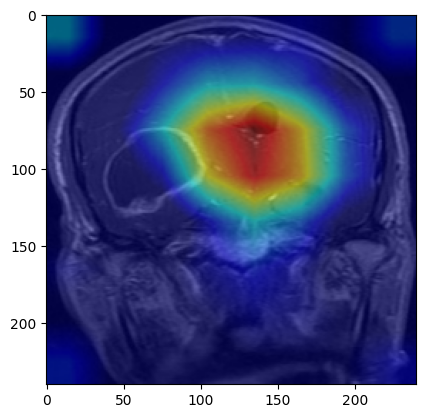

In [72]:
test_img=cv2.imread("/content/Test-Data/glioma/0.jpg")
VizGradCAM(model,img_to_array(test_img),plot_results=True)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 228ms/step


/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: [['keras_tensor']]
Received: inputs=Tensor(shape=(1, 240, 240, 3))
  warnings.warn(msg)


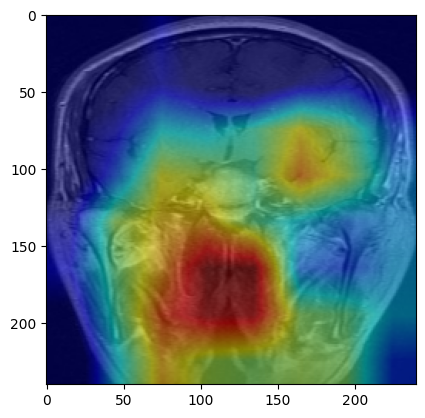

In [73]:
test_img2=cv2.imread("/content/Test-Data/pituitary/0.jpg")
VizGradCAM(model,img_to_array(test_img2),plot_results=True)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step


/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: [['keras_tensor']]
Received: inputs=Tensor(shape=(1, 240, 240, 3))
  warnings.warn(msg)


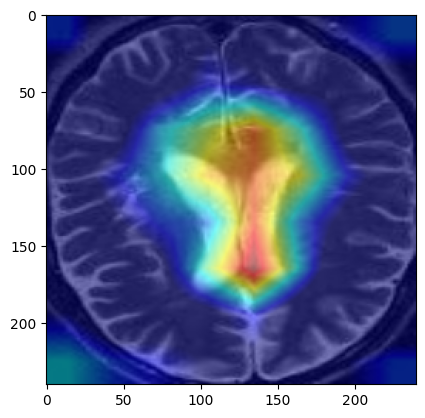

In [74]:
test_img3=cv2.imread("/content/Test-Data/no_tumor/0.jpg")
VizGradCAM(model,img_to_array(test_img3),plot_results=True)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 247ms/step


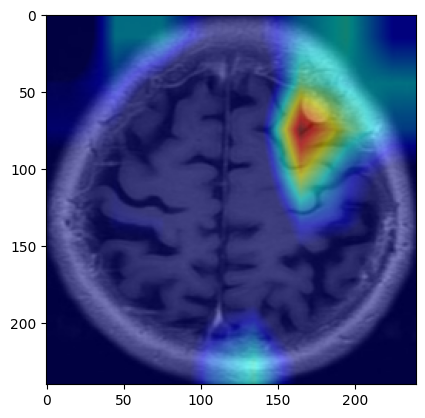

In [75]:
test_img=cv2.imread("/content/Test-Data/meningioma/0.jpg")
VizGradCAM(model,img_to_array(test_img),plot_results=True)